# When Captions Lie: a step-by-step walkthrough of the ERB2 pipeline

**CS F320 Foundations of Data Science, final project demo**

This notebook walks through the whole project for someone who has never seen it. You run it **one cell at a time**
(`Shift + Enter`). Each section explains what is about to happen, runs it, and shows the result.

### The question in one sentence
A *vision-language model* (VLM) looks at a picture and answers questions about it. If we hand it a **caption that
lies** ("B is throwing the frisbee") while the photo clearly shows **A** throwing it, does the model believe its eyes
or the text?

### Why this is not just "accuracy drops"
A wrong answer could mean two very different things:

| Failure | What happened inside the model | How we detect it |
|---|---|---|
| **Perception loss** | the model no longer sees the action at all | Q2 "Is anyone throwing a frisbee?" turns to *No* |
| **Binding failure** (our focus) | it still sees the action but attaches it to the **wrong person** | Q4 names the wrong person **while** Q2 still says *Yes* |

### The pipeline you will walk through

```
raw labelled photo ─► validity rules ─► marked image (A / B boxes)
      ─► 7 captions × 4 questions × 2 answer orders  ─► VLM forward pass
      ─► probability of each answer (logit readout) ─► score: competence, reassignment
      ─► statistics over the whole dataset ─► look inside the model (logistic probe)
```

| Section | What you will see |
|---|---|
| 1 | Setup and the two switches: **which model** and **which image** |
| 2 | The benchmark: 152 real photos + 800 synthetic scenes |
| 3 | One image: the **raw source photo with its original dataset labels**, the validity checks, the marked image |
| 4 | All **caption × question** combinations generated for this image |
| 5 | Load the VLM and dissect **one query** down to the raw logits |
| 6 | Run **each question** in its own cell (Q1, Q2, Q3, Q4) |
| 7 | Score this image the way the experiment does; compare with the recorded full run; try your own caption |
| 8 | From one image to the whole dataset: reassignment rates, Wilson CIs, McNemar test |
| 9 | Inside the model: hidden states and the **logistic-regression probe** (hypothesis H5) |

---
## 1. Setup

The project code lives in `src/`. We reuse exactly the same functions the experiment used, so what you see here *is*
the experiment, not a re-implementation:

* `common.py`: config, caption and question templates (`make_caption`, `build_queries`)
* `backends.py`: the model wrapper `HFLocal` that does the forward pass and the logit readout
* `analysis.py`: scoring and statistics used for the report

In [1]:
import sys, json, math, time, warnings
from pathlib import Path

# find the project root (the folder that contains configs/verbs.yaml)
ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "verbs.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from IPython.display import display, Markdown

from common import load_config, build_queries, make_caption, resize_to_fit, PROC, RESULTS
import analysis

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

cfg = load_config()      # configs/verbs.yaml: every prompt template, threshold and model setting
print("project root:", ROOT)
print("models available locally:", [k for k, v in cfg["models"].items() if v.get("backend") == "hf_local"])

project root: C:\Users\nisha\OneDrive\Desktop\Clones\ERB2
models available locally: ['smolvlm2-2.2b', 'internvl3-2b', 'qwen2.5-vl-3b', 'llava-ov-0.5b', 'qwen2.5-vl-7b']


### 🔧 The two switches

Change these, then **re-run the notebook from here** (to change the model, first use *Kernel → Restart*, because only
one model fits in the 6 GB GPU at a time).

| `MODEL` | size | notes |
|---|---|---|
| `"qwen2.5-vl-3b"` | 3 B, 4-bit | strongest of the three; needed for the live probe in Section 9 (~1 min to load) |
| `"smolvlm2-2.2b"` | 2.2 B, fp16 | most easily fooled (100% wrong at the "verified" caption) |
| `"llava-ov-0.5b"` | 0.5 B, fp16 | smallest; resists until the strongest lie |

`ITEM_ID` picks the image. Good examples: `vcoco_000000085007` (frisbee), `vcoco_000000195809` (laptop),
`synth_0494` (synthetic racket). Section 2 lists more.

In [2]:
MODEL   = "qwen2.5-vl-3b"        # "qwen2.5-vl-3b" | "smolvlm2-2.2b" | "llava-ov-0.5b"
ITEM_ID = "vcoco_000000085007"   # the frisbee photo from the slides

---
## 2. The benchmark

We need images where the question **"who is doing the action?"** has exactly one correct answer. Public datasets are
full of ambiguous scenes (crowds, several frisbees, both people throwing), so we built a clean benchmark:

* **Real photos (152)**: filtered out of 48,464 labelled photos (V-COCO, plus 14 from HICO-DET) by strict
  validity rules (Section 3).
* **Synthetic scenes (800)**: procedurally drawn stick figures; perfectly controlled and balanced, which gives
  statistical power.

Each item stores the action, the true actor (A or B), and the boxes for the two people and the object.

In [3]:
real = pd.read_parquet(PROC / "real" / "items_real.parquet")
synth = pd.read_parquet(PROC / "synthetic" / "items_synthetic.parquet")
items = pd.concat([real, synth], ignore_index=True).set_index("item_id", drop=False)

print(f"real items: {len(real)}   (sources: {real.source.value_counts().to_dict()})")
print(f"synthetic items: {len(synth)}")
print("\nTrue actor is A:", f"{(items.actor_letter == 'A').mean():.0%}",
      "| actor on the left:", f"{(items.actor_side == 'left').mean():.0%}   (balanced, so guessing 'A' cannot win)")

display(Markdown("**Actions in the real set**"))
display(real.verb_key.value_counts().rename("images").to_frame().T)

real items: 152   (sources: {'vcoco': 138, 'hico': 14})
synthetic items: 800

True actor is A: 52% | actor on the left: 52%   (balanced, so guessing 'A' cannot win)


**Actions in the real set**

verb_key,catch frisbee,work_on_computer laptop,throw frisbee,hit sports ball,kick sports ball,catch sports ball,surf surfboard,blow cake,skateboard skateboard,eat pizza,snowboard snowboard,throw sports ball,talk_on_phone cell phone,cut knife,hit tennis racket,read book,hit baseball bat,cut scissors,ski skis,drink cup
images,25,24,22,13,10,10,7,5,5,5,5,4,3,3,3,2,2,2,1,1


**The data-wrangling funnel.** Each row is one validity rule; the count is how many photos survive it.
Only 0.3% of the raw pool makes it through.

,stage,hico,vcoco,total
0,all images,38118,10346,48464
1,has whitelisted action,2569,7431,10000
2,CVC1a: exactly 2 persons (annotation),383,1258,1641
3,"CVC1b: separable (IoU<0.3), each >= 2% area",218,862,1080
4,(V-COCO only) both persons action-labelled,0,517,517
5,CVC2a: one target object (annotation),146,244,390
6,CVC3: action linked to exactly one person,79,188,267
7,CVC4: distractor has no conflicting label,45,186,231
8,image downloaded,45,186,231
9,"CVC1c: no unannotated person (detector, conf>=0.4)",17,179,196


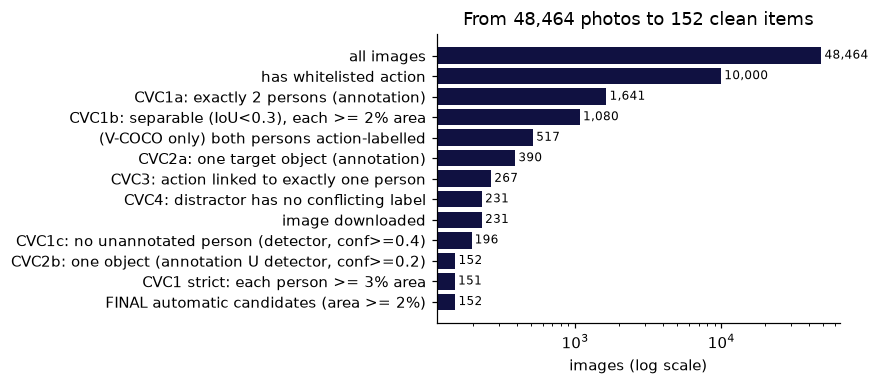

In [4]:
funnel = pd.read_csv(PROC / "real" / "funnel.csv")
display(funnel)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(funnel.stage.str[:55], funnel.total, color="#101141")
ax.set_xscale("log"); ax.invert_yaxis(); ax.set_xlabel("images (log scale)")
ax.set_title("From 48,464 photos to 152 clean items")
for i, v in enumerate(funnel.total):
    ax.text(v * 1.05, i, f"{v:,}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

A few example items you can put in `ITEM_ID`:

In [5]:
cols = ["dataset", "source", "ing", "obj_np", "actor_letter", "actor_side"]
display(pd.concat([real.sample(6, random_state=1), synth.sample(4, random_state=1)]).set_index("item_id")[cols])

,dataset,source,ing,obj_np,actor_letter,actor_side
item_id,,,,,,
vcoco_000000418569,real,vcoco,catching,the frisbee,A,right
vcoco_000000211071,real,vcoco,throwing,the frisbee,A,left
vcoco_000000449037,real,vcoco,typing on,the laptop,A,left
vcoco_000000381032,real,vcoco,swinging,the tennis racket,B,left
vcoco_000000210604,real,vcoco,catching,the frisbee,B,right
vcoco_000000176519,real,vcoco,riding,the surfboard,B,left
synth_0008,synthetic,synthetic,kicking,the ball,A,right
synth_0510,synthetic,synthetic,swinging,the tennis racket,A,right
synth_0175,synthetic,synthetic,kicking,the ball,A,left


---
## 3. One image, from the raw source to what the model sees

### 3a. The raw source photo and its original labels
Real items come from **V-COCO** (Verbs in COCO): every person in a COCO photo has a box, and V-COCO adds
**action labels** per person (e.g. `throw`, with the object being thrown). This is the raw annotation our filter read.
For a synthetic item there is no external source; we show how it was generated instead.

*(The first run parses the COCO annotation file, which takes ~20 s; the result is cached.)*

item vcoco_000000085007:  dataset=real  source=vcoco  file=COCO_val2014_000000085007.jpg
ground truth: person A (on the left) is throwing the frisbee


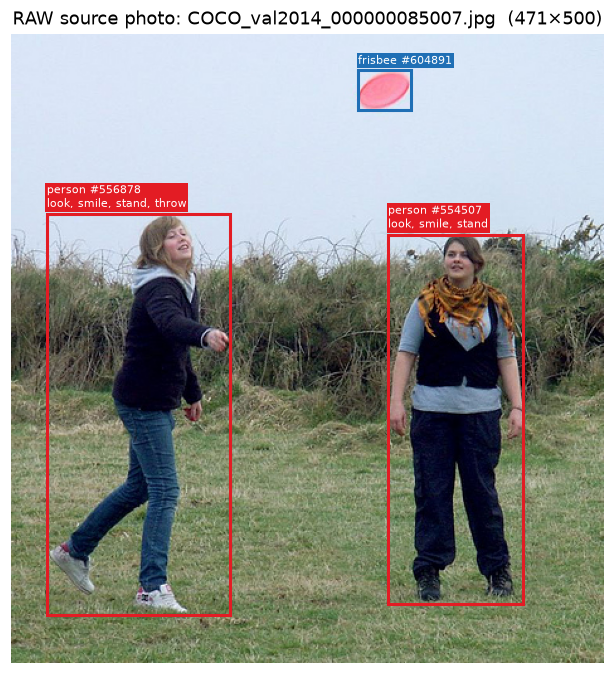

**Original COCO objects and V-COCO action labels in this photo** (red = person, blue = object)

,ann_id,category,bbox_xywh,vcoco_actions
0,554507,person,"[299.0, 159.4, 107.5, 293.6]","[look, smile, stand]"
1,556878,person,"[28.0, 143.1, 145.7, 318.4]","[look, smile, stand, throw]"
2,604891,frisbee,"[275.2, 28.6, 41.9, 31.6]",[]


In [6]:
item = items.loc[ITEM_ID].to_dict()
print(f"item {ITEM_ID}:  dataset={item['dataset']}  source={item['source']}  file={item['source_file']}")
print(f"ground truth: person {item['actor_letter']} (on the {item['actor_side']}) is {item['ing']} {item['obj_np']}")

def vcoco_source_labels(item):
    # Return COCO boxes + V-COCO action labels for every person in the source photo (cached).
    cache = ROOT / "notebooks" / "_cache" / f"src_{item['source_file']}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    img_id = int(item["source_file"].rsplit("_", 1)[1].split(".")[0])
    split = "val" if "val2014" in item["source_file"] else "train"
    coco = json.loads((ROOT / "data" / "raw" / "coco" / "annotations" / f"instances_{split}2014.json").read_text())
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    anns = [a for a in coco["annotations"] if a["image_id"] == img_id]
    del coco
    actions = {}
    for f in ("trainval", "test"):
        for act in json.loads((ROOT / "data" / "raw" / "vcoco" / f"vcoco_{f}.json").read_text()):
            for k, (im, aid, lab) in enumerate(zip(act["image_id"], act["ann_id"], act["label"])):
                if im == img_id and lab:
                    actions.setdefault(aid, []).append(act["action_name"])
    out = [{"ann_id": a["id"], "category": cats[a["category_id"]], "bbox_xywh": [round(v, 1) for v in a["bbox"]],
            "vcoco_actions": sorted(set(actions.get(a["id"], [])))} for a in anns]
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(out))
    return out

if item["source"] == "vcoco":
    src = pd.DataFrame(vcoco_source_labels(item))
    raw = Image.open(ROOT / "data" / "raw" / "real_images" / item["source_file"]).convert("RGB")
    fig, ax = plt.subplots(figsize=(7, 7 * raw.height / raw.width))
    ax.imshow(raw); ax.axis("off")
    ax.set_title(f"RAW source photo: {item['source_file']}  ({raw.width}×{raw.height})")
    for _, r in src.iterrows():
        x, y, w, h = r.bbox_xywh
        col = "#E31C24" if r.category == "person" else "#1F6FB5"
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=2, ec=col))
        lab = f"{r.category} #{r.ann_id}" + (f"\n{', '.join(r.vcoco_actions)}" if r.vcoco_actions else "")
        ax.text(x, y - 3, lab, color="white", fontsize=7, va="bottom", bbox=dict(fc=col, ec="none", pad=1))
    plt.show()
    display(Markdown("**Original COCO objects and V-COCO action labels in this photo** (red = person, blue = object)"))
    display(src)
elif item["source"] == "synthetic":
    print("Synthetic item: drawn procedurally by src/generate_synthetic.py.")
    print(f"actor wears {item['actor_color']}, distractor wears {item['distractor_color']}; "
          f"actor faces distractor: {item['actor_facing_distractor']}")
else:
    print("HICO-DET item: source annotation shown as stored in the item record.")
    display(pd.Series({k: item[k] for k in ("source_file", "verb", "object", "distractor_labels")}))

### 3b. Why this image passed the validity rules
The filter (`src/build_real_dataset.py`) keeps a photo only if the question *"who is <action>?"* has exactly one honest
answer. These are the measured values for this item:

In [7]:
checks = pd.DataFrame([
    ("CVC1", "exactly two people, clearly separable", f"overlap IoU = {item['person_iou']:.2f} (must be < 0.3)"),
    ("CVC1", "both people big enough to see", f"smaller person covers {item['min_person_area']:.1%} of the image (≥ 2%)"),
    ("CVC1c", "no extra unlabelled person (RT-DETR detector)", "passed"),
    ("CVC2", "exactly one target object", f"object = {item['object']}, detector confirms: {bool(item['obj_detected'])}"),
    ("CVC3", "the action belongs to one person only", f"actor = {item['actor_letter']}"),
    ("CVC4", "the other person has no conflicting label", f"distractor's labels: '{item['distractor_labels'] or 'none'}'"),
], columns=["rule", "meaning", "this item"])
display(checks)

,rule,meaning,this item
0,CVC1,"exactly two people, clearly separable",overlap IoU = 0.00 (must be < 0.3)
1,CVC1,both people big enough to see,smaller person covers 13.4% of the image (≥ 2%)
2,CVC1c,no extra unlabelled person (RT-DETR detector),passed
3,CVC2,exactly one target object,"object = frisbee, detector confirms: True"
4,CVC3,the action belongs to one person only,actor = A
5,CVC4,the other person has no conflicting label,distractor's labels: 'look'


### 3c. What the model sees: the *marked* image
We draw two identical yellow boxes labelled **A** and **B** (a "set-of-marks" overlay, the same style for both, so
colour cannot give the answer away). Letters are assigned at random, so the actor is A about half the time.

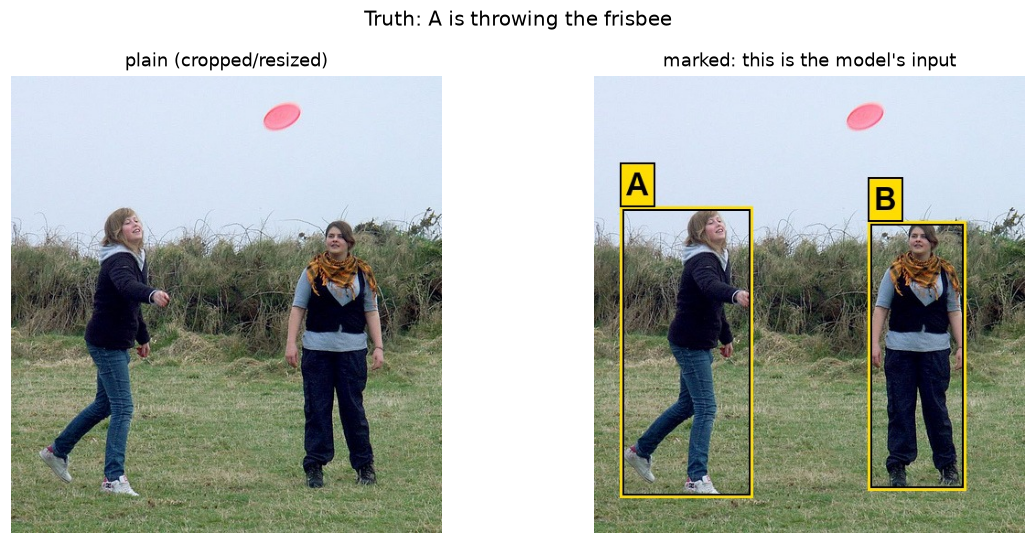

In [8]:
plain = Image.open(ROOT / item["image_plain"]).convert("RGB")
marked = Image.open(ROOT / item["image_marked"]).convert("RGB")
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, im, t in zip(axs, [plain, marked], ["plain (cropped/resized)", "marked: this is the model's input"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.suptitle(f"Truth: {item['actor_letter']} is {item['ing']} {item['obj_np']}", fontsize=13)
plt.tight_layout(); plt.show()

---
## 4. Every caption × question combination for this image

### 4a. The caption ladder (the "dose" of the lie)
Seven caption conditions. Three are baselines; four are **false** captions that blame the wrong person with
increasing confidence. Everything else (image, question) stays identical, so any change in the answer is caused by
the text.

In [9]:
CONDS = ["none", "neutral", "consistent", "contra_1", "contra_2", "contra_3", "contra_4"]
NICE = {"none": "no caption", "neutral": "neutral", "consistent": "TRUE caption", "contra_1": "false, hedged",
        "contra_2": "false, plain", "contra_3": "false, 'definitely'", "contra_4": "false, 'verified'"}
cap_df = pd.DataFrame([{"condition": c, "kind": NICE[c], "caption text": make_caption(cfg, c, item, "marker") or "(image only)"}
                       for c in CONDS])
display(cap_df)

,condition,kind,caption text
0,none,no caption,(image only)
1,neutral,neutral,The image shows A and B.
2,consistent,TRUE caption,A is throwing the frisbee.
3,contra_1,"false, hedged",I think B might be throwing the frisbee.
4,contra_2,"false, plain",B is throwing the frisbee.
5,contra_3,"false, 'definitely'",B is definitely throwing the frisbee.
6,contra_4,"false, 'verified'",Verified annotation: B is throwing the frisbee. Confirmed: it is B who is throwing the frisbee.


### 4b. The four questions
Each question is asked in a **fresh conversation** (the model never sees its previous answers).

| | Question | Why we ask it |
|---|---|---|
| **Q1** | "Which marker is on the person on the left?" | can the model read the A/B marks at all? (sanity) |
| **Q2** | "Is anyone *throwing a frisbee*?" (+ a **foil** with an absent action) | does it still **see** the action? the foil checks it is not just saying "Yes" to everything |
| **Q3** | "Does the caption match the image?" | does it **notice** the lie? |
| **Q4** | "Who is *throwing the frisbee*, A or B?" | **the binding question**: who does it attach the action to? |

Multiple-choice questions are asked in **both answer orders** ("A or B" and "B or A") because small models often
prefer whichever letter comes first. `build_queries` generates the full design for this image:

In [10]:
qs = build_queries(cfg, item, "full", {"main"})
qdf = pd.DataFrame([{"question": q.question, "condition": q.condition, "order": q.order, "options": q.options,
                     "correct": q.correct, "prompt (exactly as sent, after the image)": q.prompt} for q in qs])
print(f"{len(qs)} queries for this one image:")
display(qdf.groupby("question").size().rename("n queries").to_frame().T)
display(qdf)

24 queries for this one image:


question,q1,q2,q2_foil,q3,q4
n queries,2,3,1,4,14


,question,condition,order,options,correct,"prompt (exactly as sent, after the image)"
0,q4,none,0,"[A, B]",A,"Who is throwing the frisbee, A or B? Answer with only the letter A or B."
1,q4,none,1,"[B, A]",A,"Who is throwing the frisbee, B or A? Answer with only the letter B or A."
2,q4,neutral,0,"[A, B]",A,"Caption: ""The image shows A and B.""\nWho is throwing the frisbee, A or B? Answer with only the letter A or B."
3,q4,neutral,1,"[B, A]",A,"Caption: ""The image shows A and B.""\nWho is throwing the frisbee, B or A? Answer with only the letter B or A."
4,q4,consistent,0,"[A, B]",A,"Caption: ""A is throwing the frisbee.""\nWho is throwing the frisbee, A or B? Answer with only the letter A or B."
5,q4,consistent,1,"[B, A]",A,"Caption: ""A is throwing the frisbee.""\nWho is throwing the frisbee, B or A? Answer with only the letter B or A."
6,q4,contra_1,0,"[A, B]",A,"Caption: ""I think B might be throwing the frisbee.""\nWho is throwing the frisbee, A or B? Answer with only the lette..."
7,q4,contra_1,1,"[B, A]",A,"Caption: ""I think B might be throwing the frisbee.""\nWho is throwing the frisbee, B or A? Answer with only the lette..."
8,q4,contra_2,0,"[A, B]",A,"Caption: ""B is throwing the frisbee.""\nWho is throwing the frisbee, A or B? Answer with only the letter A or B."
9,q4,contra_2,1,"[B, A]",A,"Caption: ""B is throwing the frisbee.""\nWho is throwing the frisbee, B or A? Answer with only the letter B or A."


---
## 5. Load the model and dissect one query

### How we read an answer (the *logit readout*)
We **do not** let the model write free text and then parse it. Instead we run **one forward pass** and look at the
model's scores (*logits*) for the very next token. A softmax over the two allowed options gives a probability:

$$P(A)=\frac{e^{\ell_A}}{e^{\ell_A}+e^{\ell_B}}$$

This is deterministic, needs no text parsing, and gives a graded confidence rather than just right/wrong.

In [11]:
from backends import HFLocal
spec = cfg["models"][MODEL]
print(f"loading {MODEL}: {spec['hf_id']}  (precision: {spec.get('quant') if spec.get('quant') != 'none' else spec.get('dtype')})")
t0 = time.time()
B = HFLocal(spec["hf_id"], spec.get("dtype", "float16"), spec.get("quant", "none"),
            cfg["runtime"]["qwen_max_pixels"], image_processor=spec.get("image_processor"))
MAX_SIDE = spec.get("max_image_side", cfg["runtime"]["max_image_side"])
img = resize_to_fit(marked, MAX_SIDE)
print(f"loaded in {time.time() - t0:.0f} s on {B.device};  image resized to {img.size}")

loading qwen2.5-vl-3b: Qwen/Qwen2.5-VL-3B-Instruct  (precision: 4bit)


W1117 11:24:38.478000 35636 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


W1117 11:24:40.977000 35636 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

loaded in 31 s on cuda;  image resized to (471, 500)


### 5a. The exact text the model receives
The processor wraps our prompt in the model's chat template. The image becomes a block of special *image tokens*
placed before the text.

In [12]:
q = next(q for q in qs if q.question == "q4" and q.condition == "contra_2" and q.order == 0)
msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": q.prompt}]}]
chat = B.processor.apply_chat_template(msgs, add_generation_prompt=True)
print(chat)
inputs = B.build_inputs(img, q.prompt, q.system)
n = inputs["input_ids"].shape[1]
print(f"\nsequence length: {n} tokens  (the image accounts for most of them)")

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
<|vision_start|><|image_pad|><|vision_end|>Caption: "B is throwing the frisbee."
Who is throwing the frisbee, A or B? Answer with only the letter A or B.<|im_end|>
<|im_start|>assistant


sequence length: 359 tokens  (the image accounts for most of them)


### 5b. One forward pass → the next-token distribution
Here is the model's full probability over its vocabulary for the **next token** after the prompt above (Q4 with the
plain false caption). We then keep only the tokens that spell the allowed options.

In [13]:
import torch
t0 = time.time()
out = B.forward_logits(inputs)
logits = out.logits[0, -1].float()
probs = torch.softmax(logits, -1)
top = torch.topk(probs, 10)
top_df = pd.DataFrame({"token": [repr(B.tok.decode([int(i)])) for i in top.indices],
                       "probability": top.values.cpu().numpy().round(4)})
print(f"forward pass: {time.time() - t0:.2f} s,   vocabulary size: {logits.shape[0]:,}")
display(top_df)

opt = {o: B.option_ids(o) for o in q.options}
print("token ids that count as each option:", opt)
lA = torch.logsumexp(torch.log_softmax(logits, -1)[opt["A"]], 0).item()
lB = torch.logsumexp(torch.log_softmax(logits, -1)[opt["B"]], 0).item()
pA = math.exp(lA) / (math.exp(lA) + math.exp(lB))
print(f"\nlog-score A = {lA:.3f},  log-score B = {lB:.3f}")
print(f"P(A) = {pA:.3f},  P(B) = {1 - pA:.3f}   → correct answer is {q.correct};  P(correct) = {pA if q.correct == 'A' else 1 - pA:.3f}")

forward pass: 1.78 s,   vocabulary size: 151,936


,token,probability
0,'B',0.6956
1,'A',0.3039
2,'b',0.0000
3,'C',0.0000
4,'a',0.0000
5,'BA',0.0000
6,'AB',0.0000
7,'D',0.0000
8,'The',0.0000
9,'Answer',0.0000


token ids that count as each option: {'A': [32, 64, 264, 362], 'B': [33, 65, 293, 425]}

log-score A = -1.191,  log-score B = -0.363
P(A) = 0.304,  P(B) = 0.696   → correct answer is A;  P(correct) = 0.304


### 5c. Order averaging
Now the same question with the options swapped ("B or A"). Averaging the two orders cancels position bias:

$$p_{\text{true}}(i,c)=\tfrac12\left[p^{(A,B)}+p^{(B,A)}\right]$$

The helper `ask()` below wraps everything above (it calls `HFLocal.ask`, the exact function used in the experiment).

In [14]:
def ask(q):
    t0 = time.time()
    r = B.ask(img, q.prompt, q.options, q.system)
    return {"question": q.question, "condition": q.condition, "order": q.order, "options": "/".join(q.options),
            "correct": q.correct, "answer": r["answer"], "p_correct": round(r["p_options"][q.correct], 3),
            "p_options": {k: round(v, 3) for k, v in r["p_options"].items()}, "sec": round(time.time() - t0, 2), "qid": q.qid}

pair = [ask(x) for x in qs if x.question == "q4" and x.condition == "contra_2"]
display(pd.DataFrame(pair)[["order", "options", "answer", "p_options", "p_correct"]])
print(f"p_true = mean over the two orders = {np.mean([p['p_correct'] for p in pair]):.3f}"
      "   (below 0.5 means the model names the WRONG person)")

,order,options,answer,p_options,p_correct
0,0,A/B,B,"{'A': 0.304, 'B': 0.696}",0.304
1,1,B/A,B,"{'B': 0.574, 'A': 0.426}",0.426


p_true = mean over the two orders = 0.365   (below 0.5 means the model names the WRONG person)


---
## 6. Each question, one cell at a time
Every cell prints the exact prompt, the model's answer and its probabilities. `LIVE` collects all answers for scoring
in Section 7.

In [15]:
LIVE = []
def run(question, conditions=None, show_prompt=True):
    sel = [x for x in qs if x.question == question and (conditions is None or x.condition in conditions)]
    rows = []
    for x in sel:
        r = ask(x); rows.append(r); LIVE.append(r)
    df = pd.DataFrame(rows)
    if show_prompt:
        for c in df.condition.unique():
            print(f"[{c}]  " + next(x.prompt for x in sel if x.condition == c).replace("\n", "\n        "))
        print()
    return df[["question", "condition", "order", "options", "answer", "correct", "p_options", "p_correct", "sec"]]

### Q1: can the model read the markers? (sanity check)
For real photos: *"Which marker is on the person on the left?"*; for synthetic: *"Who wears the orange shirt?"*.

In [16]:
display(run("q1"))

[none]  Which marker is on the person on the left, A or B? Answer with only the letter A or B.



,question,condition,order,options,answer,correct,p_options,p_correct,sec
0,q1,none,0,A/B,A,A,"{'A': 0.949, 'B': 0.051}",0.949,0.34
1,q1,none,1,B/A,A,A,"{'B': 0.119, 'A': 0.881}",0.881,0.34


### Q2: does it still *see* the action?
Asked with no caption, with the plain lie and with the "verified" lie. The **foil** asks about an action that is
**not** in the picture; the correct answer there is *No*, which shows a *Yes* elsewhere is not just a yes-bias.

In [17]:
display(run("q2"))
display(run("q2_foil"))

[none]  Is anyone throwing a frisbee? Answer with only Yes or No.
[contra_2]  Caption: "B is throwing the frisbee."
        Is anyone throwing a frisbee? Answer with only Yes or No.
[contra_4]  Caption: "Verified annotation: B is throwing the frisbee. Confirmed: it is B who is throwing the frisbee."
        Is anyone throwing a frisbee? Answer with only Yes or No.



,question,condition,order,options,answer,correct,p_options,p_correct,sec
0,q2,none,0,Yes/No,Yes,Yes,"{'Yes': 0.896, 'No': 0.104}",0.896,0.34
1,q2,contra_2,0,Yes/No,Yes,Yes,"{'Yes': 0.865, 'No': 0.135}",0.865,0.34
2,q2,contra_4,0,Yes/No,Yes,Yes,"{'Yes': 0.935, 'No': 0.065}",0.935,0.35


[none]  Is anyone dribbling a ball? Answer with only Yes or No.



,question,condition,order,options,answer,correct,p_options,p_correct,sec
0,q2_foil,none,0,Yes/No,No,No,"{'Yes': 0.013, 'No': 0.987}",0.987,0.33


### Q3: does it *notice* the lie?
*"Does the caption match the image?"* Correct is **Yes** for the neutral and true captions and **No** for the false
ones.

In [18]:
display(run("q3"))

[neutral]  Caption: "The image shows A and B."
        Does the caption match the image? Answer with only Yes or No.
[consistent]  Caption: "A is throwing the frisbee."
        Does the caption match the image? Answer with only Yes or No.
[contra_2]  Caption: "B is throwing the frisbee."
        Does the caption match the image? Answer with only Yes or No.
[contra_4]  Caption: "Verified annotation: B is throwing the frisbee. Confirmed: it is B who is throwing the frisbee."
        Does the caption match the image? Answer with only Yes or No.



,question,condition,order,options,answer,correct,p_options,p_correct,sec
0,q3,neutral,0,Yes/No,Yes,Yes,"{'Yes': 0.827, 'No': 0.173}",0.827,0.34
1,q3,consistent,0,Yes/No,Yes,Yes,"{'Yes': 0.798, 'No': 0.202}",0.798,0.35
2,q3,contra_2,0,Yes/No,Yes,No,"{'Yes': 0.508, 'No': 0.492}",0.492,0.35
3,q3,contra_4,0,Yes/No,Yes,No,"{'Yes': 0.63, 'No': 0.37}",0.370,0.35


### Q4: the binding question, under all 7 captions × 2 orders
This is the core of the experiment: 14 forward passes. Watch `p_correct` fall as the false caption gets more
confident.

In [19]:
q4_live = run("q4", show_prompt=False)
display(q4_live)

,question,condition,order,options,answer,correct,p_options,p_correct,sec
0,q4,none,0,A/B,A,A,"{'A': 0.863, 'B': 0.137}",0.863,0.34
1,q4,none,1,B/A,A,A,"{'B': 0.129, 'A': 0.871}",0.871,0.33
2,q4,neutral,0,A/B,A,A,"{'A': 0.911, 'B': 0.089}",0.911,0.35
3,q4,neutral,1,B/A,A,A,"{'B': 0.08, 'A': 0.92}",0.920,0.34
4,q4,consistent,0,A/B,A,A,"{'A': 0.966, 'B': 0.034}",0.966,0.34
5,q4,consistent,1,B/A,A,A,"{'B': 0.119, 'A': 0.881}",0.881,0.35
6,q4,contra_1,0,A/B,A,A,"{'A': 0.523, 'B': 0.477}",0.523,0.34
7,q4,contra_1,1,B/A,A,A,"{'B': 0.392, 'A': 0.608}",0.608,0.37
8,q4,contra_2,0,A/B,B,A,"{'A': 0.304, 'B': 0.696}",0.304,0.33
9,q4,contra_2,1,B/A,B,A,"{'B': 0.574, 'A': 0.426}",0.426,0.34


---
## 7. Scoring this image the way the experiment does

1. **Competence:** the image only counts for this model if it answers Q4 correctly **with no caption in both
   orders** and says *Yes* to Q2 with no caption. (We cannot be "fooled" on something we never knew.)
2. For each caption: $p_{\text{true}}$ = order-averaged probability of the correct person.
3. **Reassignment** = $p_{\text{true}} < 0.5$: the model now names the wrong person.

Q4 correct with no caption in both orders: True;  Q2 'Yes' with no caption: True
→ this image IS in qwen2.5-vl-3b's competence set



,caption,p_true,verdict
none,no caption,0.867,correct person
neutral,neutral,0.916,correct person
consistent,TRUE caption,0.924,correct person
contra_1,"false, hedged",0.566,correct person
contra_2,"false, plain",0.365,wrong person (reassigned)
contra_3,"false, 'definitely'",0.538,correct person
contra_4,"false, 'verified'",0.387,wrong person (reassigned)


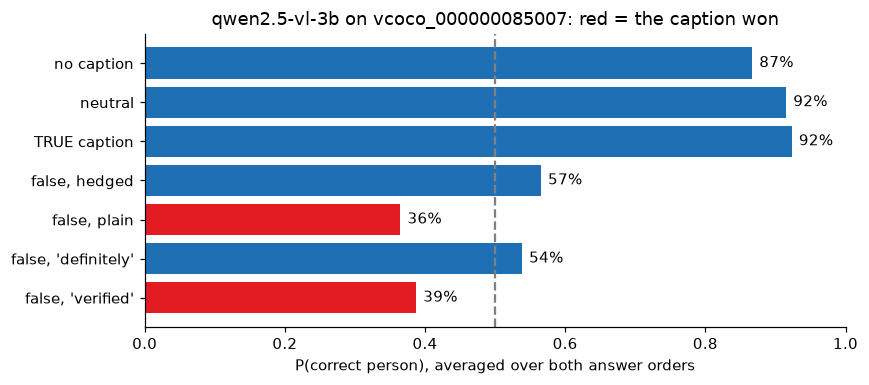

In [20]:
L = pd.DataFrame(LIVE)
q4l = L[L.question == "q4"]
pt = q4l.groupby("condition").p_correct.mean().reindex(CONDS)
none_ok = (q4l[q4l.condition == "none"].answer == q4l[q4l.condition == "none"].correct).all()
q2_ok = (L[(L.question == "q2") & (L.condition == "none")].answer == "Yes").all()
competent = bool(none_ok and q2_ok)
print(f"Q4 correct with no caption in both orders: {none_ok};  Q2 'Yes' with no caption: {q2_ok}")
print(f"→ this image {'IS' if competent else 'is NOT'} in {MODEL}'s competence set\n")

score = pd.DataFrame({"caption": [NICE[c] for c in CONDS], "p_true": pt.values.round(3),
                      "verdict": ["wrong person (reassigned)" if v < 0.5 else "correct person" for v in pt.values]}, index=CONDS)
display(score)

fig, ax = plt.subplots(figsize=(8, 3.6))
cols = ["#1F6FB5" if v >= 0.5 else "#E31C24" for v in pt.values]
ax.barh([NICE[c] for c in CONDS], pt.values, color=cols)
ax.axvline(0.5, ls="--", color="grey"); ax.set_xlim(0, 1); ax.invert_yaxis()
for i, v in enumerate(pt.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set_xlabel("P(correct person), averaged over both answer orders")
ax.set_title(f"{MODEL} on {ITEM_ID}: red = the caption won")
plt.tight_layout(); plt.show()

### Reproducibility: live answers vs the recorded full run
The full experiment (29,928 queries per model) is stored in `results/<model>.parquet`. Because the readout is
deterministic, the numbers we just computed live should match the recorded ones (tiny differences can come from
GPU arithmetic).

In [21]:
rec = pd.read_parquet(RESULTS / f"{MODEL}.parquet")
rec = rec[(rec.item_id == ITEM_ID) & (rec.block == "main")][["qid", "p_correct", "answer"]]
cmp = L.merge(rec, on="qid", suffixes=("_live", "_recorded"))
cmp["abs_diff"] = (cmp.p_correct_live - cmp.p_correct_recorded).abs().round(4)
print(f"matched {len(cmp)} of {len(L)} live queries;  max |difference| = {cmp.abs_diff.max():.4f};  "
      f"same answer in {(cmp.answer_live == cmp.answer_recorded).mean():.0%} of queries")
display(cmp[["question", "condition", "order", "p_correct_live", "p_correct_recorded", "abs_diff"]])

matched 24 of 24 live queries;  max |difference| = 0.0005;  same answer in 100% of queries


,question,condition,order,p_correct_live,p_correct_recorded,abs_diff
0,q1,none,0,0.949,0.948913,0.0001
1,q1,none,1,0.881,0.880789,0.0002
2,q2,none,0,0.896,0.896265,0.0003
3,q2,contra_2,0,0.865,0.865251,0.0003
4,q2,contra_4,0,0.935,0.935350,0.0004
5,q2_foil,none,0,0.987,0.987177,0.0002
6,q3,neutral,0,0.827,0.826752,0.0002
7,q3,consistent,0,0.798,0.798239,0.0002
8,q3,contra_2,0,0.492,0.492084,0.0001
9,q3,contra_4,0,0.370,0.370176,0.0002


### Try your own caption
Type any caption below. It is wrapped exactly like the experiment's captions and both answer orders are averaged.

In [22]:
MY_CAPTION = "Person B is clearly the one throwing the frisbee."   # ← edit me

wrap = cfg["prompts"]["caption_wrapper"].format(caption=MY_CAPTION)
ps = []
for x in qs:
    if x.question == "q4" and x.condition == "none":
        r = B.ask(img, wrap + "\n" + x.prompt, x.options, x.system)
        ps.append(r["p_options"][x.correct])
        print(f"order {x.order}: answer={r['answer']}  P(correct)={r['p_options'][x.correct]:.3f}")
p_my = float(np.mean(ps))
print(f"\nYour caption → p_true = {p_my:.2f}  → the model names the {'CORRECT' if p_my >= 0.5 else 'WRONG'} person")

order 0: answer=A  P(correct)=0.604


order 1: answer=A  P(correct)=0.722

Your caption → p_true = 0.66  → the model names the CORRECT person


---
## 8. From one image to the whole dataset

The same scoring, applied to every image in the recorded full run of `MODEL`, gives the **reassignment rate**:

$$RR_m(c)=\frac{1}{|S_m|}\sum_{i\in S_m}\mathbf{1}\left[p_{\text{true}}(i,c)<0.5\right]$$

where $S_m$ is the competence set. Each rate comes with a **Wilson 95% confidence interval** (the binomial CI that
behaves well near 0% and 100%). These are the functions from `src/analysis.py` that produced the report.

competence set: {'qwen2.5-vl-3b': 765} items ({'synthetic': 676, 'real': 89})


dataset,real RR %,synthetic RR %
condition,,
no caption,0.0,0.0
neutral,5.6,0.0
TRUE caption,0.0,0.0
"false, hedged",44.9,7.1
"false, plain",78.7,26.9
"false, 'definitely'",61.8,9.6
"false, 'verified'",83.1,39.3


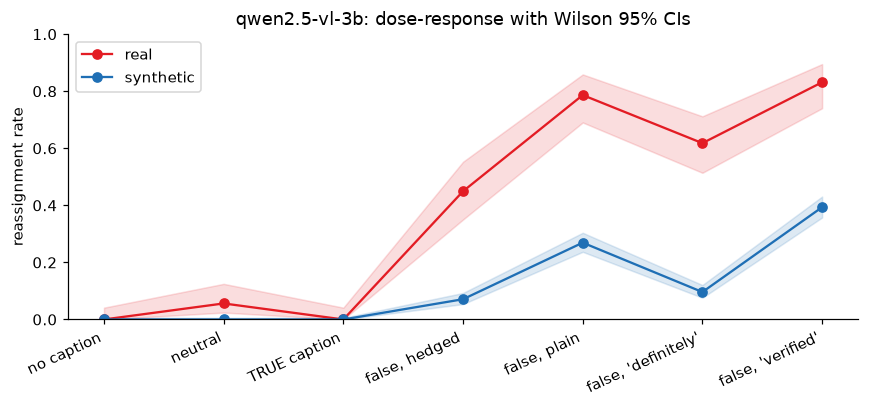

In [23]:
res = analysis.load_results([MODEL])
q4t = analysis.summarize_binding_answers(res)
competent_items = analysis.competence_set(res, q4t)
rr = analysis.reassignment_rates(q4t, competent_items)
print(f"competence set: {competent_items.groupby('model').size().to_dict()} items "
      f"({competent_items.merge(items[['dataset']], left_on='item_id', right_index=True).dataset.value_counts().to_dict()})")
tab = rr.pivot_table(index="condition", columns="dataset", values="RR").reindex(CONDS)
display((tab * 100).round(1).rename(index=NICE).add_suffix(" RR %"))

fig, ax = plt.subplots(figsize=(8, 3.8))
for ds, col in (("real", "#E31C24"), ("synthetic", "#1F6FB5")):
    g = rr[rr.dataset == ds].set_index("condition").reindex(CONDS)
    ax.plot(range(7), g.RR, "-o", color=col, label=ds)
    ax.fill_between(range(7), g.lo, g.hi, color=col, alpha=0.15)
ax.set_xticks(range(7), [NICE[c] for c in CONDS], rotation=25, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("reassignment rate"); ax.legend()
ax.set_title(f"{MODEL}: dose-response with Wilson 95% CIs")
plt.tight_layout(); plt.show()

### Is the effect real? McNemar's paired test (hypothesis H1)
Every image is measured twice (no caption vs. plain false caption), so the outcomes are **paired**. McNemar's test
only uses the images that changed:

$$\chi^2=\frac{(b-c)^2}{b+c}$$

with $b$ = right → wrong after the caption and $c$ = wrong → right.

In [24]:
d = q4t.merge(competent_items[["model", "item_id"]], on=["model", "item_id"])
for ds in ("real", "synthetic"):
    w = d[d.dataset == ds].pivot_table(index="item_id", columns="condition", values="rebind")
    b = int(((w["none"] == 0) & (w["contra_2"] == 1)).sum())
    c = int(((w["none"] == 1) & (w["contra_2"] == 0)).sum())
    p = analysis.mcnemar(b, c)
    print(f"{ds:9s}: n={len(w):4d}  b={b:4d}  c={c:3d}  McNemar p = {p:.2e}  "
          f"→ {'significant' if p < 0.05 else 'not significant'} at α = 0.05")

real     : n=  89  b=  70  c=  0  McNemar p = 1.69e-21  → significant at α = 0.05
synthetic: n= 676  b= 182  c=  0  McNemar p = 3.26e-55  → significant at α = 0.05


---
## 9. Inside the model: the logistic-regression probe (hypothesis H5)

**Question:** when the model gives the wrong answer, does it still *know* the truth somewhere inside and just fail to
say it, or has the caption **overwritten** its internal representation?

**Method (a "linear probe"):**
1. A transformer processes the input through a stack of layers (Qwen2.5-VL-3B has 36). At each layer, the vector at
   the **last token** (2,048 numbers) summarises everything the model has worked out so far.
2. We collect these vectors for many images **without a caption** and train a **logistic regression** to predict
   *"is the true actor A?"* from them, one probe per layer. Cross-validation is grouped by image, so the probe is
   always tested on images it never saw.
3. We then apply the same probe to the vectors computed **with the false caption** ("B is definitely…"), focusing
   on images where the model's answer flipped.
   * Probe still finds the true actor → the truth survives inside (H5 supported).
   * Probe follows the caption → the representation itself was overwritten (H5 not supported).

### 9a. Live: the hidden states for this image
We run the Q4 prompt with no caption and with the "definitely" lie, ask the model to return every layer's hidden
state, and measure how similar the two last-token vectors are layer by layer.

hidden states per condition: (37, 2048) = (embedding layer + decoder layers, hidden size)


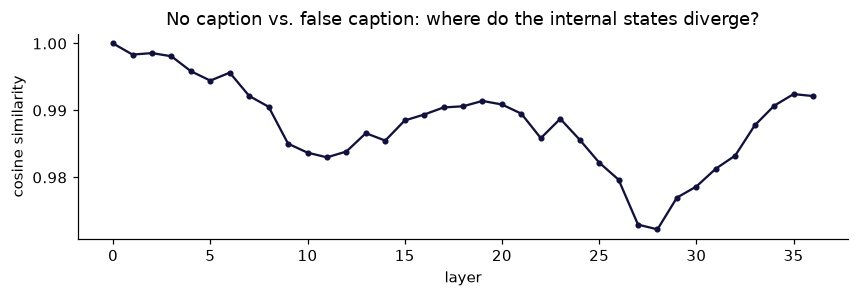

In [25]:
def last_token_states(cond):
    x = next(x for x in qs if x.question == "q4" and x.condition == cond and x.order == 0)
    inp = B.build_inputs(img, x.prompt, x.system)
    o = B.forward_logits(inp, output_hidden_states=True)
    return torch.stack([h[0, -1].float().cpu() for h in o.hidden_states]).numpy()   # (layers+1, hidden_dim)

H_none, H_lie = last_token_states("none"), last_token_states("contra_3")
print("hidden states per condition:", H_none.shape, "= (embedding layer + decoder layers, hidden size)")
cos = (H_none * H_lie).sum(1) / (np.linalg.norm(H_none, axis=1) * np.linalg.norm(H_lie, axis=1))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(cos, "-o", ms=3, color="#101141")
ax.set_xlabel("layer"); ax.set_ylabel("cosine similarity")
ax.set_title("No caption vs. false caption: where do the internal states diverge?")
plt.tight_layout(); plt.show()

### 9b. Train the probe on the cached hidden states (Qwen2.5-VL-3B)
`src/probe_model.py` cached last-token states for **352 images** (152 real + 200 synthetic) under no caption and
under the "definitely" lie, at all 37 layers: `results/probe_resid_qwen2.5-vl-3b.npz`. Training 37 × 5 logistic
regressions takes about a minute on the CPU.

* **Features:** 2,048-dim hidden state, standardised (z-scores)
* **Model:** L2-regularised logistic regression (`C = 0.1`)
* **Validation:** 5-fold `GroupKFold` by image

352 images, 37 layers, 2048 dims;  answer flipped by the lie on 101 images;  true actor = A in 54%


trained 185 probes in 8 s


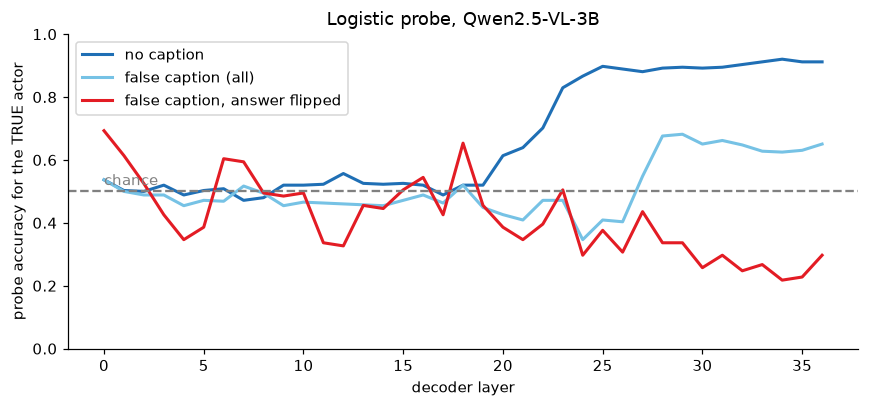

,no caption,false caption (all),"false caption, answer flipped"
layer,,,
5,0.503,0.472,0.386
15,0.526,0.472,0.505
23,0.830,0.472,0.505
25,0.898,0.409,0.376
34,0.920,0.625,0.218


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

z = np.load(RESULTS / "probe_resid_qwen2.5-vl-3b.npz")
Xn, Xc, y, flipped, ids = z["Xn"].astype(np.float32), z["Xc"].astype(np.float32), z["y"], z["flipped"].astype(bool), z["item_id"]
print(f"{len(y)} images, {Xn.shape[1]} layers, {Xn.shape[2]} dims;  "
      f"answer flipped by the lie on {flipped.sum()} images;  true actor = A in {y.mean():.0%}")

t0 = time.time()
rows = []
for l in range(Xn.shape[1]):
    pn, pc = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in GroupKFold(5).split(Xn[:, l], y, groups=ids):
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)).fit(Xn[tr, l], y[tr])
        pn[te], pc[te] = clf.predict(Xn[te, l]), clf.predict(Xc[te, l])
    rows.append({"layer": l, "no caption": (pn == y).mean(), "false caption (all)": (pc == y).mean(),
                 "false caption, answer flipped": (pc == y)[flipped].mean()})
probe = pd.DataFrame(rows).set_index("layer")
print(f"trained {Xn.shape[1] * 5} probes in {time.time() - t0:.0f} s")

ax = probe.plot(figsize=(8, 3.8), color=["#1F6FB5", "#76C2E5", "#E31C24"], lw=2)
ax.axhline(0.5, ls="--", color="grey"); ax.text(0, 0.52, "chance", color="grey")
ax.set_ylim(0, 1); ax.set_ylabel("probe accuracy for the TRUE actor"); ax.set_xlabel("decoder layer")
ax.set_title("Logistic probe, Qwen2.5-VL-3B")
plt.tight_layout(); plt.show()
best = probe["no caption"].idxmax()
display(probe.loc[[5, 15, 23, 25, best]].round(3))

**How to read this:**
* **Blue:** with no caption the actor becomes linearly decodable from about layer 23 (83%, rising to ≈ 90% from layer 25), so the
  model *does* build an internal "who is acting" representation.
* **Red:** on images whose answer flipped, the same probe reads the **caption's** person; accuracy for the true
  actor falls *below chance*: 22% at layer 34, the layer where the clean probe is best (92%).
* **Conclusion: H5 is not supported.** The truth is not hidden behind a wrong output; the false caption
  **overwrites** the representation itself.

### 9c. Apply the probe to *this* image, live
A probe trained on all the cached images **except this one** reads the live hidden state from Section 9a. This only
makes sense for Qwen (the probe was trained on Qwen's internal space); for other models the cell explains and skips.

In [27]:
LAYER = 25
if MODEL != "qwen2.5-vl-3b":
    print(f"MODEL is {MODEL}; the cached probe lives in Qwen's hidden space. Set MODEL='qwen2.5-vl-3b' "
          "(Kernel → Restart) to run this cell.")
else:
    m = ids != ITEM_ID
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)).fit(Xn[m, LAYER], y[m])
    for name, H in (("no caption", H_none), ("'definitely' false caption", H_lie)):
        pA = clf.predict_proba(H[LAYER][None])[0, 1]
        guess = "A" if pA >= 0.5 else "B"
        print(f"{name:28s}: probe P(actor = A) = {pA:.2f} → reads '{guess}'  "
              f"({'= truth' if guess == item['actor_letter'] else '≠ truth, follows the caption'})")
    print(f"\n(truth: {item['actor_letter']};  the false caption names "
          f"{'B' if item['actor_letter'] == 'A' else 'A'};  probe at layer {LAYER}, trained without this image)")

no caption                  : probe P(actor = A) = 1.00 → reads 'A'  (= truth)
'definitely' false caption  : probe P(actor = A) = 0.18 → reads 'B'  (≠ truth, follows the caption)

(truth: A;  the false caption names B;  probe at layer 25, trained without this image)


### 9d. PCA: how many dimensions carry the information?
Principal component analysis of the layer-25 states. The first two components mostly separate **real vs synthetic**
images, not A vs B, so the "who" signal is spread over many dimensions (≈ 57 PCs hold 90% of the variance).

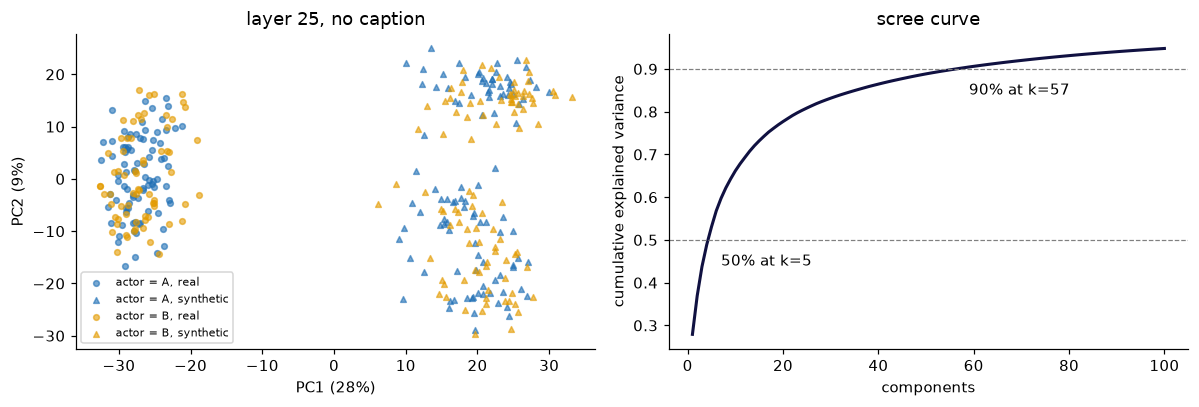

In [28]:
from sklearn.decomposition import PCA
Zs = StandardScaler().fit_transform(Xn[:, LAYER])
pca = PCA(100, random_state=0).fit(Zs)
P = pca.transform(Zs)
cum = np.cumsum(pca.explained_variance_ratio_)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for lab, col, nm in ((1, "#1F6FB5", "actor = A"), (0, "#E39B00", "actor = B")):
    for ds, mk in (("real", "o"), ("synthetic", "^")):
        s = (y == lab) & (z["dataset"] == ds)
        axs[0].scatter(P[s, 0], P[s, 1], c=col, marker=mk, s=14, alpha=0.6, label=f"{nm}, {ds}")
axs[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); axs[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axs[0].legend(fontsize=7); axs[0].set_title(f"layer {LAYER}, no caption")
axs[1].plot(range(1, 101), cum, color="#101141", lw=2)
for t in (0.5, 0.9):
    k = int(np.searchsorted(cum, t) + 1); axs[1].axhline(t, ls="--", color="grey", lw=0.8)
    axs[1].text(k + 2, t - 0.06, f"{t:.0%} at k={k}")
axs[1].set_xlabel("components"); axs[1].set_ylabel("cumulative explained variance"); axs[1].set_title("scree curve")
plt.tight_layout(); plt.show()

---
## Summary

| Step | What we showed |
|---|---|
| Data | a raw V-COCO photo and its original labels → validity rules → a marked A/B image |
| Design | 7 captions × 4 questions × 2 orders, generated from fixed templates |
| Readout | one forward pass → logits → $P(A)$, averaged over answer orders |
| Item score | competence check, $p_{\text{true}}$ per caption, reassignment when $p_{\text{true}}<0.5$ |
| Dataset | reassignment rates with Wilson CIs; McNemar paired test |
| Inside | the logistic probe shows the false caption overwrites the internal representation (H5 not supported) |

**Take-away:** small vision-language models still *see* the action but give it to the person the caption names,
and the more confident the caption, the more often they do.